# Task 1: Face Recognition with Embedding Comparison

**Goal:** Build and compare two embedding approaches:
- **Method 1:** Classification-based CNN (Softmax + CrossEntropy)
- **Method 2:** Metric Learning CNN (Triplet Loss, Random Mining)

**Evaluation:** ROC Curve + AUC on `verification_pairs_val.txt` using Cosine & Euclidean distance

```
dataset/
├── classification_data/
│   ├── train_data/   # 4000 identities
│   ├── val_data/     # 4000 identities
│   └── test_data/
├── verification_data/       # flat folder of images
├── verification_pairs_val.txt
└── verification_pairs_test.txt
```

## Section 0 – Setup & Imports

In [1]:
mkdir -p ~/.kaggle && echo KGAT_481a09343ecc7630e831143a9136dd78 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [2]:
import sys
!{sys.executable} -m pip install kagglehub torch torchvision scikit-learn matplotlib seaborn tqdm Pillow numpy

In [3]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('11-785-fall-20-homework-2-part-2')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2


In [4]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import csv

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import roc_curve, auc, accuracy_score

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# --- Device ---
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print(f'Using device: {DEVICE}')

# --- Paths ---
PROJECT_ROOT = Path('.')
DATA_ROOT    = PROJECT_ROOT / '/root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2'

TRAIN_DIR  = DATA_ROOT / 'classification_data' / 'train_data'
VAL_DIR    = DATA_ROOT / 'classification_data' / 'val_data'
TEST_DIR   = DATA_ROOT / 'classification_data' / 'test_data'
VERIF_DIR  = DATA_ROOT / 'verification_data'
VAL_PAIRS  = DATA_ROOT / 'verification_pairs_val.txt'
TEST_PAIRS = DATA_ROOT / 'verification_pairs_test.txt'
SAMPLE_SUB = DATA_ROOT / 'hw2p2_sample_submission.csv'

CKPT_DIR   = PROJECT_ROOT / 'checkpoints'
EMBED_DIR  = PROJECT_ROOT / 'embeddings'
RESULT_DIR = PROJECT_ROOT / 'results'

for d in [CKPT_DIR, EMBED_DIR, RESULT_DIR]:
    d.mkdir(exist_ok=True)

# --- Hyperparameters ---
IMG_SIZE       = 112
EMBED_DIM      = 512
BATCH_SIZE     = 32
NUM_WORKERS    = 8
EPOCHS         = 35
LR             = 1e-4       
ARCFACE_S      = 32.0       
ARCFACE_M      = 0.35       
TRIPLET_MARGIN = 0.3

print('Setup complete.')

Using device: cuda
Setup complete.


## Section 1 – Data Exploration (EDA)

In [5]:
def count_dataset(root):
    identities = sorted([d for d in root.iterdir() if d.is_dir()])
    imgs_per_id = [len(list(d.glob('*.jpg')) + list(d.glob('*.png'))) for d in identities]
    return identities, imgs_per_id

train_ids, train_counts = count_dataset(TRAIN_DIR)
val_ids,   val_counts   = count_dataset(VAL_DIR)
test_ids,  test_counts  = count_dataset(TEST_DIR)

print(f'Train: {len(train_ids):,} identities | {sum(train_counts):,} images | mean {np.mean(train_counts):.1f}/id')
print(f'Val  : {len(val_ids):,} identities | {sum(val_counts):,} images | mean {np.mean(val_counts):.1f}/id')
print(f'Test : {len(test_ids):,} identities | {sum(test_counts):,} images')

verif_imgs = list(VERIF_DIR.glob('*.jpg'))
print(f'Verification images: {len(verif_imgs):,}')

with open(VAL_PAIRS) as f:
    val_pairs_lines = f.read().splitlines()
same_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '1')
diff_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '0')
print(f'Val pairs: {len(val_pairs_lines):,} | Same={same_pairs:,} | Diff={diff_pairs:,}')

Train: 4,000 identities | 380,638 images | mean 95.2/id
Val  : 4,000 identities | 8,000 images | mean 2.0/id
Test : 4,000 identities | 8,000 images
Verification images: 69,097
Val pairs: 8,805 | Same=4,315 | Diff=4,490


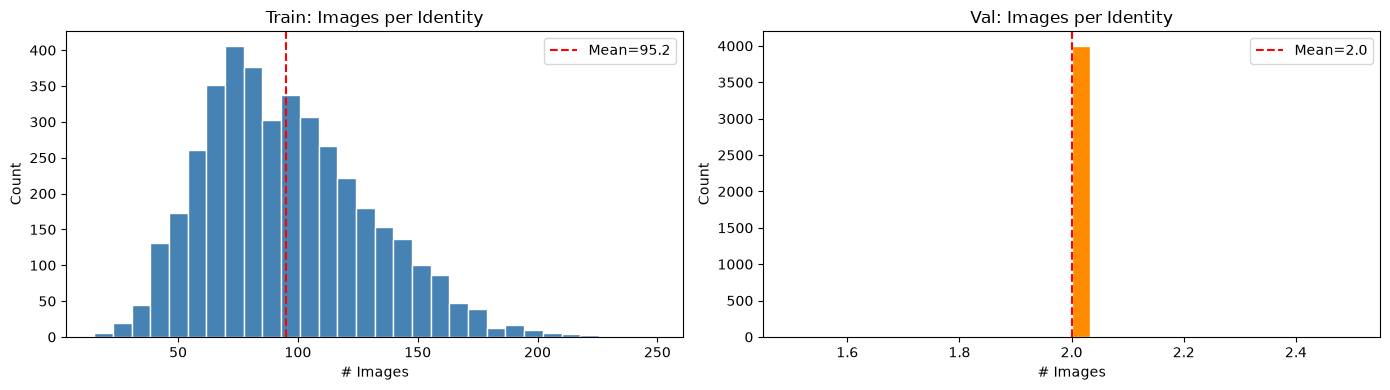

In [6]:
# Distribution of images per identity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(train_counts, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Train: Images per Identity')
axes[0].set_xlabel('# Images'); axes[0].set_ylabel('Count')
axes[0].axvline(np.mean(train_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(train_counts):.1f}')
axes[0].legend()

axes[1].hist(val_counts, bins=30, color='darkorange', edgecolor='white')
axes[1].set_title('Val: Images per Identity')
axes[1].set_xlabel('# Images'); axes[1].set_ylabel('Count')
axes[1].axvline(np.mean(val_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(val_counts):.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULT_DIR / 'dataset_distribution.png', dpi=120)
plt.show()

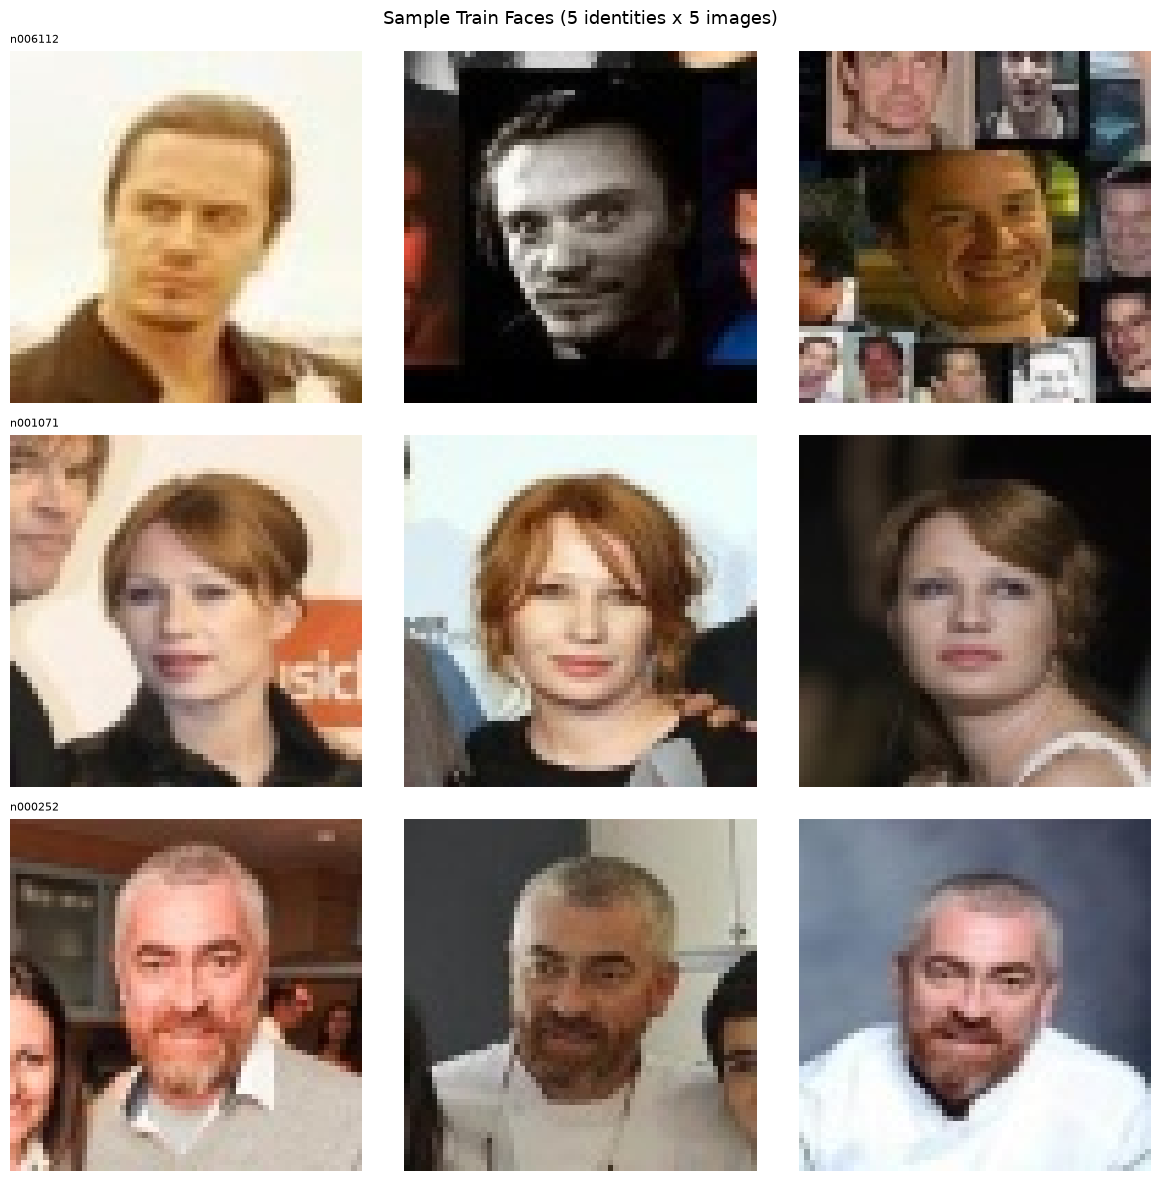

In [7]:
# Sample images grid (5 identities x 5 images)
sample_ids = random.sample(train_ids, 3)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, identity in enumerate(sample_ids):
    imgs = sorted(identity.glob('*.jpg'))[:3]
    for col, img_path in enumerate(imgs):
        ax = axes[row][col]
        img = Image.open(img_path).convert('RGB')
        ax.imshow(img)
        ax.axis('off')
        if col == 0:
            ax.set_title(identity.name, fontsize=8, loc='left')

plt.suptitle('Sample Train Faces (5 identities x 5 images)', fontsize=13)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'sample_faces.png', dpi=120)
plt.show()

## Section 2 – Datasets & DataLoaders

In [8]:
MEAN = [0.5, 0.5, 0.5]
STD  = [0.5, 0.5, 0.5]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomCrop(IMG_SIZE, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [9]:
# ---------- FaceClassificationDataset ----------
class FaceClassificationDataset(Dataset):
    """Standard folder dataset: returns (image_tensor, label_int)."""
    def __init__(self, root, transform=None):
        self.transform = transform
        self.samples   = []
        identity_dirs  = sorted([d for d in root.iterdir() if d.is_dir()])
        self.label_to_idx = {d.name: i for i, d in enumerate(identity_dirs)}
        self.num_classes  = len(identity_dirs)
        for id_dir in identity_dirs:
            label = self.label_to_idx[id_dir.name]
            for ext in ('*.jpg', '*.png'):
                for img_path in id_dir.glob(ext):
                    self.samples.append((img_path, label))
        print(f'  {root.name}: {len(self.samples):,} images, {self.num_classes:,} classes')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, label


# ---------- TripletFaceDataset ----------
class TripletFaceDataset(Dataset):
    """Returns (anchor, positive, negative) with random mining."""
    def __init__(self, root, transform=None):
        self.transform    = transform
        self.label_to_imgs = defaultdict(list)
        identity_dirs = sorted([d for d in root.iterdir() if d.is_dir()])
        for i, id_dir in enumerate(identity_dirs):
            imgs = list(id_dir.glob('*.jpg')) + list(id_dir.glob('*.png'))
            if len(imgs) >= 2:
                self.label_to_imgs[i] = imgs
        self.all_labels = list(self.label_to_imgs.keys())
        self.samples = [(img, lbl)
                        for lbl, imgs in self.label_to_imgs.items()
                        for img in imgs]
        print(f'  Triplet {root.name}: {len(self.samples):,} images, '
              f'{len(self.all_labels):,} usable identities')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        anchor_path, anchor_lbl = self.samples[idx]
        # Positive
        pos_candidates = [p for p in self.label_to_imgs[anchor_lbl] if p != anchor_path]
        pos_path = random.choice(pos_candidates)
        # Negative
        neg_lbl  = random.choice([l for l in self.all_labels if l != anchor_lbl])
        neg_path = random.choice(self.label_to_imgs[neg_lbl])

        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img

        return load(anchor_path), load(pos_path), load(neg_path)


# ---------- VerificationDataset ----------
class VerificationDataset(Dataset):
    """Reads pairs_file, returns (img1, img2, label)."""
    def __init__(self, pairs_file, transform=None, has_labels=True):
        self.transform  = transform
        self.has_labels = has_labels
        self.pairs      = []
        base_dir = pairs_file.parent
        with open(pairs_file) as f:
            for line in f:
                parts = line.strip().split()
                if has_labels and len(parts) == 3:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], int(parts[2])))
                elif not has_labels and len(parts) >= 2:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], f'{parts[0]} {parts[1]}'))
        print(f'  {pairs_file.name}: {len(self.pairs):,} pairs')

    def __len__(self):  return len(self.pairs)

    def __getitem__(self, idx):
        p1, p2, meta = self.pairs[idx]
        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img
        return load(p1), load(p2), meta

In [10]:
print('=== Building Datasets ===')
clf_train_ds = FaceClassificationDataset(TRAIN_DIR, transform=train_transform)
clf_val_ds   = FaceClassificationDataset(VAL_DIR,   transform=val_transform)
NUM_CLASSES  = clf_train_ds.num_classes

triplet_train_ds = TripletFaceDataset(TRAIN_DIR, transform=train_transform)

verif_val_ds  = VerificationDataset(VAL_PAIRS,  transform=val_transform, has_labels=True)
verif_test_ds = VerificationDataset(TEST_PAIRS, transform=val_transform, has_labels=False)

# DataLoaders
clf_train_loader = DataLoader(clf_train_ds,   batch_size=BATCH_SIZE,    shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
clf_val_loader   = DataLoader(clf_val_ds,     batch_size=BATCH_SIZE,    shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
triplet_loader   = DataLoader(triplet_train_ds, batch_size=BATCH_SIZE//2, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
verif_val_loader = DataLoader(verif_val_ds,   batch_size=128, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
verif_test_loader= DataLoader(verif_test_ds,  batch_size=128, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

print('\nAll DataLoaders ready.')

=== Building Datasets ===
  train_data: 380,638 images, 4,000 classes
  val_data: 8,000 images, 4,000 classes
  Triplet train_data: 380,638 images, 4,000 usable identities
  verification_pairs_val.txt: 8,805 pairs
  verification_pairs_test.txt: 51,835 pairs

All DataLoaders ready.


## Section 3 – CNN Architecture

In [11]:
# --- Building Blocks ---
class ConvBlock(nn.Module):
    """Conv3x3 -> BN -> ReLU -> optional MaxPool2d(2)"""
    def __init__(self, in_ch, out_ch, pool=False):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool: layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)

    def forward(self, x): return self.block(x)


class ResBlock(nn.Module):
    """Lightweight residual block (same spatial size in/out)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch),
        )

    def forward(self, x): return F.relu(self.net(x) + x, inplace=True)


# --- Backbone ---
class FaceCNN(nn.Module):
    """
    Custom CNN backbone.
    Input : (B, 3, 112, 112)
    Output: (B, embed_dim) – L2-normalized

    Spatial flow:  112 -> 56 -> 28 -> 14 -> 7 -> 3 -> 1
    Channels:        3    32    64   128   256   512
    """
    def __init__(self, embed_dim=512):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32,  pool=True),   # 112->56
            ConvBlock(32,  64,  pool=True),   # 56->28
            ResBlock(64),
            ConvBlock(64,  128, pool=True),   # 28->14
            ResBlock(128),
            ConvBlock(128, 256, pool=True),   # 14->7
            ResBlock(256),
            ConvBlock(256, 512, pool=True),   # 7->3
            nn.AdaptiveAvgPool2d(1),          # 3->1
        )
        self.emb_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, embed_dim),
            nn.BatchNorm1d(embed_dim),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.emb_head(x)
        return F.normalize(x, p=2, dim=1)   # L2-normalize


# --- Method 1: Classification model ---
class FaceCNN_Classifier(nn.Module):
    def __init__(self, num_classes, embed_dim=512):
        super().__init__()
        self.backbone   = FaceCNN(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        emb    = self.backbone(x)
        logits = self.classifier(emb)
        return logits, emb

    def get_embedding(self, x): return self.backbone(x)


# --- Method 2: Triplet model ---
class FaceCNN_Triplet(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)

    def forward(self, a, p, n):
        return self.backbone(a), self.backbone(p), self.backbone(n)

    def get_embedding(self, x): return self.backbone(x)


# Quick check
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    print(f'  Total params: {total:,}')

print('=== FaceCNN_Classifier ===')
_m = FaceCNN_Classifier(NUM_CLASSES, EMBED_DIM)
count_params(_m)
_x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
_logits, _emb = _m(_x)
print(f'  logits: {_logits.shape} | embedding: {_emb.shape}')
del _m, _x, _logits, _emb

# --- ArcFace margin head ---
class ArcFaceHead(nn.Module):
    """
    ArcFace (Additive Angular Margin) classification head.
    Replaces the standard linear classifier with a cosine-similarity head
    that adds an angular margin *m* before the softmax during training.
    Reference: Deng et al. (2019) – ArcFace: Additive Angular Margin Loss for
               Deep Face Recognition.
    """
    def __init__(self, embed_dim: int, num_classes: int,
                 s: float = 64.0, m: float = 0.5):
        super().__init__()
        self.s = s
        self.m = m
        self.weight = nn.Parameter(torch.empty(num_classes, embed_dim))
        nn.init.xavier_uniform_(self.weight)

        # Precompute constants
        import math
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th    = math.cos(math.pi - m)   # threshold = cos(π – m)
        self.mm    = math.sin(math.pi - m) * m

    def forward(self, embeddings, labels=None):
        # Normalise weights -> cosine similarity
        w_norm = F.normalize(self.weight, p=2, dim=1)
        cos_theta = F.linear(embeddings, w_norm).clamp(-1 + 1e-7, 1 - 1e-7)

        if labels is None:           # inference: plain cosine logits
            return self.s * cos_theta

        # ArcFace: add margin in angle space
        sin_theta  = torch.sqrt(1.0 - cos_theta ** 2)
        cos_theta_m = cos_theta * self.cos_m - sin_theta * self.sin_m
        # Numerical stability: where cos_theta < threshold, use linear approx
        cos_theta_m = torch.where(cos_theta > self.th, cos_theta_m,
                                  cos_theta - self.mm)
        one_hot = torch.zeros_like(cos_theta)
        one_hot.scatter_(1, labels.view(-1, 1).long(), 1.0)
        logits = (one_hot * cos_theta_m + (1.0 - one_hot) * cos_theta) * self.s
        return logits


# --- Method 3: ArcFace model ---
class FaceCNN_ArcFace(nn.Module):
    """Same FaceCNN backbone + ArcFace margin head."""
    def __init__(self, num_classes: int, embed_dim: int = 512,
                 s: float = 64.0, m: float = 0.5):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)
        self.head     = ArcFaceHead(embed_dim, num_classes, s=s, m=m)

    def forward(self, x, labels=None):
        emb    = self.backbone(x)          # L2-normalised embedding
        logits = self.head(emb, labels)
        return logits, emb

    def get_embedding(self, x):
        return self.backbone(x)


print('=== FaceCNN_ArcFace ===')
_m3 = FaceCNN_ArcFace(NUM_CLASSES, EMBED_DIM)
count_params(_m3)
_x  = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
_lb = torch.randint(0, NUM_CLASSES, (2,))
_lg, _em = _m3(_x, _lb)
print(f'  logits: {_lg.shape} | embedding: {_em.shape}')
del _m3, _x, _lb, _lg, _em


=== FaceCNN_Classifier ===
  Total params: 5,435,328
  logits: torch.Size([2, 4000]) | embedding: torch.Size([2, 512])
=== FaceCNN_ArcFace ===
  Total params: 5,431,328
  logits: torch.Size([2, 4000]) | embedding: torch.Size([2, 512])


## Section 4 – Method 3: ArcFace (Additive Angular Margin Loss)

ArcFace thay thế softmax classifier thông thường bằng **additive angular margin** trong không gian hyperspherical, giúp embedding phân biệt danh tính tốt hơn so với softmax và triplet loss.

In [12]:
def train_arcface(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Train', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits_margin, _ = model(imgs, labels)   # with margin -> for loss
        loss = criterion(logits_margin, labels)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            logits_clean, _ = model(imgs, None)  # no margin -> for accuracy
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits_clean.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def eval_arcface(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Val  ', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        logits_margin, _ = model(imgs, labels)   # with margin -> for loss
        loss = criterion(logits_margin, labels)
        logits_clean, _ = model(imgs, None)       # no margin -> for accuracy
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits_clean.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correct / total

In [13]:
# ── ArcFace hyper-params ───────────────────────────────────────────────────
ARCFACE_S   = 32.0   # logit scale (giảm từ 64 -> ổn định hơn)
ARCFACE_M   = 0.35   # angular margin in radians (giảm từ 0.5 -> hội tụ nhanh hơn)
LR_ARCFACE  = 1e-4   # tách riêng để không ảnh hưởng M1/M2

model3     = FaceCNN_ArcFace(NUM_CLASSES, EMBED_DIM, s=ARCFACE_S, m=ARCFACE_M).to(DEVICE)
criterion3 = nn.CrossEntropyLoss()   # standard CE on scaled cosine logits
optimizer3 = torch.optim.AdamW(model3.parameters(), lr=LR_ARCFACE, weight_decay=5e-4)
scheduler3 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer3, T_max=EPOCHS)

history3 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss3 = float('inf')   # save based on val LOSS (VaAcc ~0% không đủ tín hiệu)

print(f'Training Method 3 (ArcFace) for {EPOCHS} epochs on {DEVICE}...')
print(f'  s={ARCFACE_S}, m={ARCFACE_M}, lr={LR_ARCFACE}')
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_arcface(model3, clf_train_loader, criterion3, optimizer3, DEVICE)
    va_loss, va_acc = eval_arcface(model3, clf_val_loader,   criterion3, DEVICE)
    scheduler3.step()
    history3['train_loss'].append(tr_loss); history3['train_acc'].append(tr_acc)
    history3['val_loss'].append(va_loss);   history3['val_acc'].append(va_acc)
    if va_loss < best_val_loss3:   # save best checkpoint by VAL LOSS
        best_val_loss3 = va_loss
        torch.save(model3.state_dict(), CKPT_DIR / 'method3_best.pth')
        marker = ' <- BEST'
    else:
        marker = ''
    print(f'Ep {epoch:02d}/{EPOCHS} | TrLoss {tr_loss:.4f} TrAcc {tr_acc*100:.1f}% '
          f'| VaLoss {va_loss:.4f} VaAcc {va_acc*100:.1f}%{marker}')

print(f'\nBest Val Loss (M3): {best_val_loss3:.4f}')


Training Method 3 (ArcFace) for 35 epochs on cuda...
  s=32.0, m=0.35, lr=0.0001


Ep 01/35 | TrLoss 18.0202 TrAcc 2.8% | VaLoss 16.4313 VaAcc 7.2% <- BEST


Ep 02/35 | TrLoss 15.1142 TrAcc 22.1% | VaLoss 13.8917 VaAcc 27.9% <- BEST


Ep 03/35 | TrLoss 12.7731 TrAcc 41.5% | VaLoss 11.8359 VaAcc 43.4% <- BEST


Ep 04/35 | TrLoss 11.1318 TrAcc 53.3% | VaLoss 10.5772 VaAcc 53.6% <- BEST


Ep 05/35 | TrLoss 10.1672 TrAcc 60.8% | VaLoss 9.8044 VaAcc 59.8% <- BEST


... (26 outputs left out)

Ep 32/35 | TrLoss 5.4824 TrAcc 87.1% | VaLoss 6.3182 VaAcc 81.4% <- BEST


Ep 33/35 | TrLoss 5.4656 TrAcc 87.1% | VaLoss 6.3127 VaAcc 81.2% <- BEST


Ep 34/35 | TrLoss 5.4513 TrAcc 87.1% | VaLoss 6.3053 VaAcc 81.2% <- BEST


Ep 35/35 | TrLoss 5.4424 TrAcc 87.1% | VaLoss 6.3062 VaAcc 81.4%

Best Val Loss (M3): 6.3053


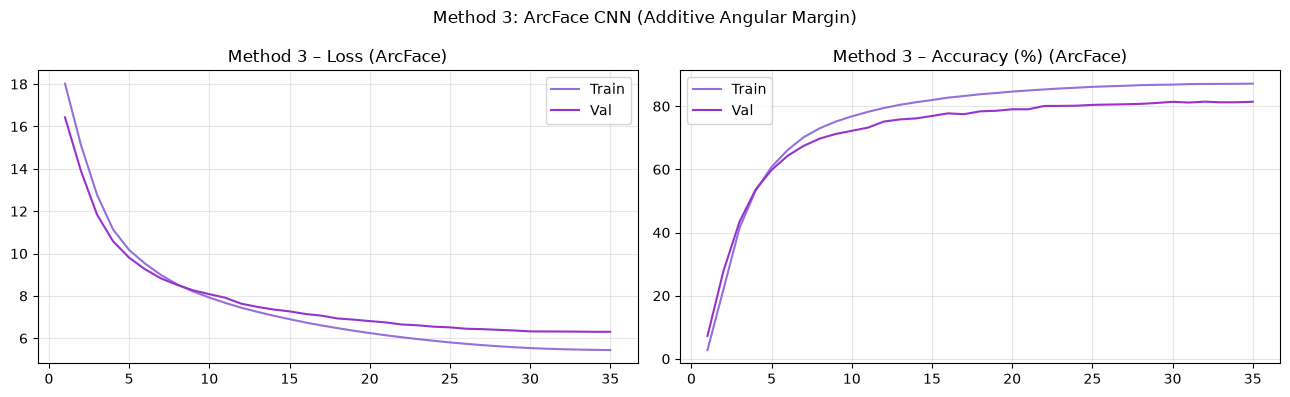

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, EPOCHS + 1)
axes[0].plot(ep, history3['train_loss'], label='Train', color='mediumpurple')
axes[0].plot(ep, history3['val_loss'],   label='Val',   color='darkorchid')
axes[0].set_title('Method 3 – Loss (ArcFace)'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a*100 for a in history3['train_acc']], label='Train', color='mediumpurple')
axes[1].plot(ep, [a*100 for a in history3['val_acc']],   label='Val',   color='darkorchid')
axes[1].set_title('Method 3 – Accuracy (%) (ArcFace)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle('Method 3: ArcFace CNN (Additive Angular Margin)', fontsize=12)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'method3_curves.png', dpi=120)
plt.show()


## Section 5 – Evaluation: ROC Curve & AUC

In [15]:
# Load best checkpoints
model1_eval = FaceCNN_Classifier(NUM_CLASSES, EMBED_DIM).to(DEVICE)
model1_eval.load_state_dict(torch.load(CKPT_DIR / 'method1_best.pth', map_location=DEVICE))
model1_eval.eval()

model2_eval = FaceCNN_Triplet(EMBED_DIM).to(DEVICE)
model2_eval.load_state_dict(torch.load(CKPT_DIR / 'method2_best.pth', map_location=DEVICE))
model2_eval.eval()

model3_eval = FaceCNN_ArcFace(NUM_CLASSES, EMBED_DIM).to(DEVICE)
model3_eval.load_state_dict(torch.load(CKPT_DIR / 'method3_best.pth', map_location=DEVICE))
model3_eval.eval()

print('Best checkpoints loaded: Method 1, Method 2, Method 3 (ArcFace).')


Best checkpoints loaded: Method 1, Method 2, Method 3 (ArcFace).


In [16]:
@torch.no_grad()
def extract_pair_embeddings(model, loader, device):
    """Returns emb1 (N,D), emb2 (N,D), labels (N,)."""
    model.eval()
    e1s, e2s, lbls = [], [], []
    for img1, img2, label in tqdm(loader, desc='  Extracting'):
        e1s.append(model.get_embedding(img1.to(device)).cpu().numpy())
        e2s.append(model.get_embedding(img2.to(device)).cpu().numpy())
        lbls.append(np.array(label))
    return np.concatenate(e1s), np.concatenate(e2s), np.concatenate(lbls)


print('Extracting Method 1 embeddings...')
e1_m1, e2_m1, lbl_m1 = extract_pair_embeddings(model1_eval, verif_val_loader, DEVICE)
np.savez(EMBED_DIR / 'method1_val.npz', emb1=e1_m1, emb2=e2_m1, labels=lbl_m1)

print('Extracting Method 2 embeddings...')
e1_m2, e2_m2, lbl_m2 = extract_pair_embeddings(model2_eval, verif_val_loader, DEVICE)
np.savez(EMBED_DIR / 'method2_val.npz', emb1=e1_m2, emb2=e2_m2, labels=lbl_m2)

print('Extracting Method 3 (ArcFace) embeddings...')
e1_m3, e2_m3, lbl_m3 = extract_pair_embeddings(model3_eval, verif_val_loader, DEVICE)
np.savez(EMBED_DIR / 'method3_val.npz', emb1=e1_m3, emb2=e2_m3, labels=lbl_m3)

print('Done.')


Extracting Method 1 embeddings...


  Extracting:   0%|          | 0/69 [00:00<?, ?it/s]/tmp/ipykernel_5081/780875364.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  lbls.append(np.array(label))
  Extracting: 100%|██████████| 69/69 [00:02<00:00, 33.46it/s]


Extracting Method 2 embeddings...


  Extracting: 100%|██████████| 69/69 [00:01<00:00, 35.95it/s]


Extracting Method 3 (ArcFace) embeddings...


  Extracting: 100%|██████████| 69/69 [00:01<00:00, 35.85it/s]

Done.


In [17]:
def cosine_sim(e1, e2):    return np.sum(e1 * e2, axis=1)              # L2-normed -> dot product
def euclidean_dist(e1, e2): return np.sqrt(np.sum((e1 - e2) ** 2, axis=1))


def compute_roc_metrics(scores, labels):
    """scores: higher => same person."""
    fpr, tpr, thrs = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = (fpr[np.nanargmin(np.abs(fnr - fpr))] + fnr[np.nanargmin(np.abs(fnr - fpr))]) / 2
    j       = tpr - fpr
    best_thr = thrs[np.argmax(j)]
    best_acc = accuracy_score(labels, (scores >= best_thr).astype(int))
    return fpr, tpr, roc_auc, eer, best_thr, best_acc


# Evaluate all 6 settings (3 models x 2 distance metrics)
settings = {
    'Method1 + Cosine':     (cosine_sim(e1_m1, e2_m1),       lbl_m1),
    'Method1 + Euclidean':  (-euclidean_dist(e1_m1, e2_m1),  lbl_m1),
    'Method2 + Cosine':     (cosine_sim(e1_m2, e2_m2),       lbl_m2),
    'Method2 + Euclidean':  (-euclidean_dist(e1_m2, e2_m2),  lbl_m2),
    'Method3 + Cosine':     (cosine_sim(e1_m3, e2_m3),       lbl_m3),
    'Method3 + Euclidean':  (-euclidean_dist(e1_m3, e2_m3),  lbl_m3),
}

results = {}
for name, (scores, labels) in settings.items():
    fpr, tpr, rac, eer, thr, acc = compute_roc_metrics(scores, labels)
    results[name] = dict(fpr=fpr, tpr=tpr, auc=rac, eer=eer, thresh=thr, acc=acc)
    print(f'{name:30s}  AUC={rac:.4f}  EER={eer*100:.2f}%  BestAcc={acc*100:.2f}%')


Method1 + Cosine                AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method1 + Euclidean             AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method2 + Cosine                AUC=0.9064  EER=17.40%  BestAcc=83.03%
Method2 + Euclidean             AUC=0.9064  EER=17.40%  BestAcc=83.03%
Method3 + Cosine                AUC=0.9400  EER=12.78%  BestAcc=87.29%
Method3 + Euclidean             AUC=0.9400  EER=12.78%  BestAcc=87.29%


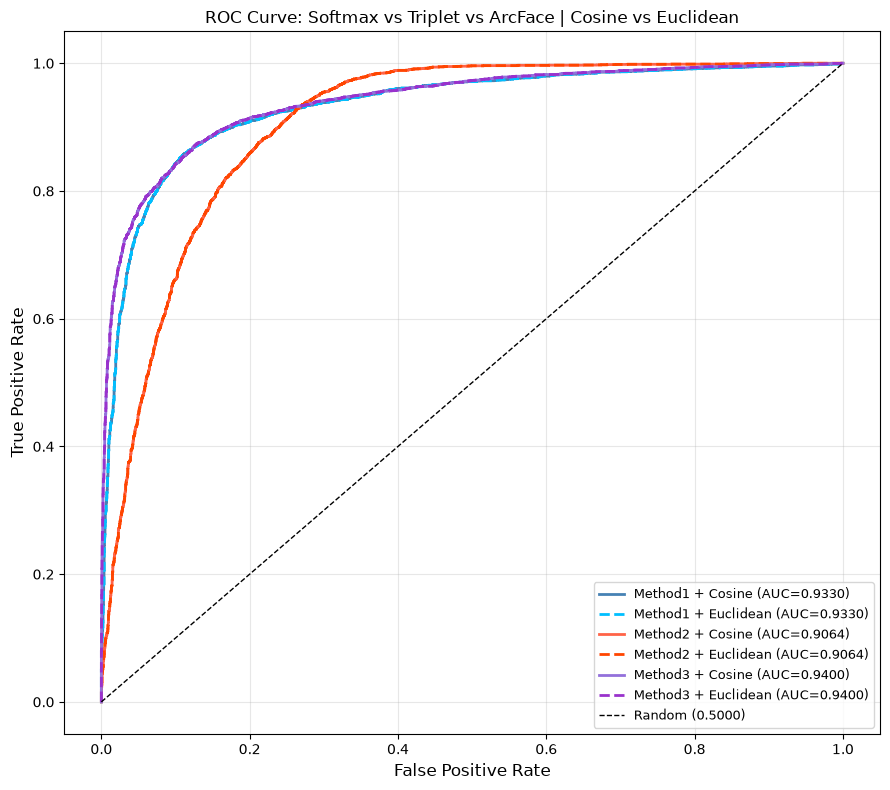

In [18]:
# ROC Curves – Method 1, 2, 3
COLORS = ['steelblue', 'deepskyblue', 'tomato', 'orangered', 'mediumpurple', 'darkorchid']
STYLES = ['-', '--', '-', '--', '-', '--']

plt.figure(figsize=(9, 8))
for (name, res), c, s in zip(results.items(), COLORS, STYLES):
    plt.plot(res['fpr'], res['tpr'], color=c, linestyle=s, lw=2,
             label=f"{name} (AUC={res['auc']:.4f})")
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (0.5000)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve: Softmax vs Triplet vs ArcFace | Cosine vs Euclidean', fontsize=12)
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'roc_curves.png', dpi=150)
plt.show()


In [19]:
# Summary table
print('=' * 80)
print(f'{"Method":<35} {"AUC":>8} {"EER":>8} {"Best Acc":>10} {"Threshold":>11}')
print('-' * 80)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    print(f'{name:<35} {res["auc"]:>8.4f} {res["eer"]*100:>7.2f}% '
          f'{res["acc"]*100:>9.2f}% {res["thresh"]:>11.4f}')
print('=' * 80)

BEST_CONFIG = max(results, key=lambda k: results[k]['auc'])
print(f'\n>> Best configuration: {BEST_CONFIG}  (AUC={results[BEST_CONFIG]["auc"]:.4f})')


Method                                   AUC      EER   Best Acc   Threshold
--------------------------------------------------------------------------------
Method3 + Euclidean                   0.9400   12.78%     87.29%     -1.2946
Method3 + Cosine                      0.9400   12.78%     87.29%      0.1620
Method1 + Cosine                      0.9330   12.94%     87.36%      0.2094
Method1 + Euclidean                   0.9330   12.94%     87.36%     -1.2575
Method2 + Euclidean                   0.9064   17.40%     83.03%     -0.9663
Method2 + Cosine                      0.9064   17.40%     83.03%      0.5331

>> Best configuration: Method3 + Euclidean  (AUC=0.9400)


Computing t-SNE (this may take ~1 min)...


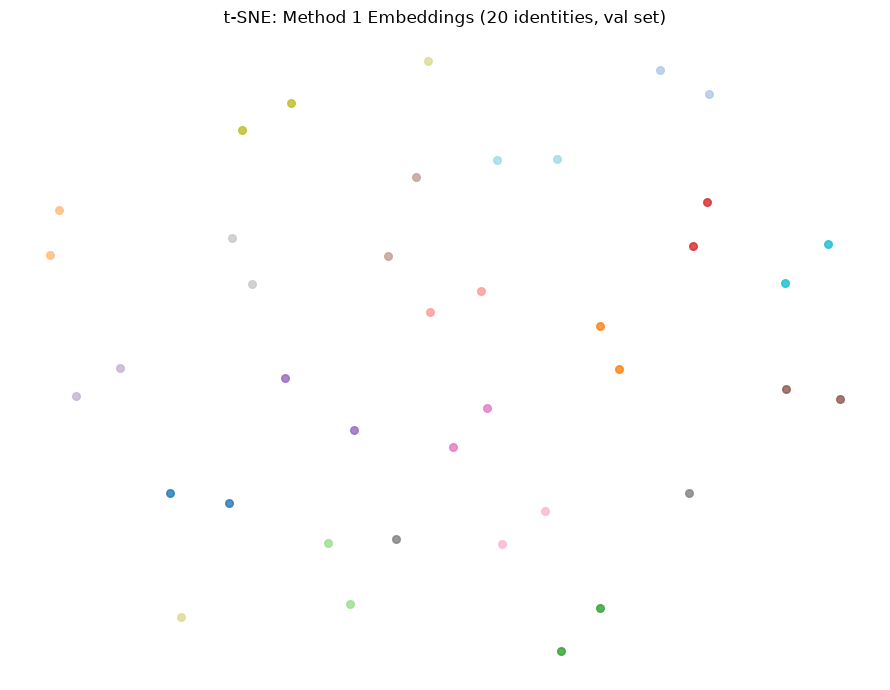

In [20]:
# t-SNE Visualization (20 identities, Method 1)
from sklearn.manifold import TSNE

@torch.no_grad()
def get_class_embeddings(model, root, n_ids=20, n_per_id=10, transform=None, device='cpu'):
    model.eval()
    id_dirs = random.sample([d for d in root.iterdir() if d.is_dir()], n_ids)
    embs, lbls = [], []
    for lbl, d in enumerate(id_dirs):
        for img_path in list(d.glob('*.jpg'))[:n_per_id]:
            img = Image.open(img_path).convert('RGB')
            if transform: img = transform(img)
            e = model.get_embedding(img.unsqueeze(0).to(device)).cpu().numpy().squeeze()
            embs.append(e); lbls.append(lbl)
    return np.array(embs), np.array(lbls)

print('Computing t-SNE (this may take ~1 min)...')
tsne_embs, tsne_lbls = get_class_embeddings(
    model1_eval, VAL_DIR, n_ids=20, n_per_id=10, transform=val_transform, device=DEVICE
)
xy = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(tsne_embs)

plt.figure(figsize=(9, 7))
colors = plt.cm.tab20(np.linspace(0, 1, 20))
for i in range(20):
    m = tsne_lbls == i
    plt.scatter(xy[m, 0], xy[m, 1], color=colors[i], s=30, alpha=0.8, label=f'ID {i}')
plt.title('t-SNE: Method 1 Embeddings (20 identities, val set)', fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.savefig(RESULT_DIR/'tsne_method1.png', dpi=120)
plt.show()

## Section 7 – Test Submission

In [21]:
# Select best model & distance based on AUC
if 'Method1' in BEST_CONFIG:
    best_eval_model = model1_eval
elif 'Method2' in BEST_CONFIG:
    best_eval_model = model2_eval
else:   # Method3 (ArcFace)
    best_eval_model = model3_eval

if 'Cosine' in BEST_CONFIG:
    score_fn  = cosine_sim
    threshold = results[BEST_CONFIG]['thresh']
else:
    score_fn  = lambda e1, e2: -euclidean_dist(e1, e2)
    threshold = results[BEST_CONFIG]['thresh']

print(f'Using: {BEST_CONFIG}')
print(f'Threshold: {threshold:.4f}')

# Extract test embeddings
@torch.no_grad()
def predict_test(model, loader, score_fn, threshold, device):
    model.eval()
    all_scores, all_meta = [], []
    for img1, img2, meta in tqdm(loader, desc='Test inference'):
        e1 = model.get_embedding(img1.to(device)).cpu().numpy()
        e2 = model.get_embedding(img2.to(device)).cpu().numpy()
        all_scores.extend(score_fn(e1, e2).tolist())
        all_meta.extend(meta)
    scores = np.array(all_scores)
    preds  = (scores >= threshold).astype(int)
    return all_meta, scores, preds

test_meta, test_scores, test_preds = predict_test(
    best_eval_model, verif_test_loader, score_fn, threshold, DEVICE
)
print(f'Test pairs: {len(test_preds):,} | Same: {test_preds.sum()} | '
      f'Diff: {(~test_preds.astype(bool)).sum()}')


Using: Method3 + Euclidean
Threshold: -1.2946


Test inference: 100%|██████████| 405/405 [00:09<00:00, 43.47it/s]

Test pairs: 51,835 | Same: 25963 | Diff: 25872


In [22]:
# Write submission.csv
sub_path = RESULT_DIR / 'submission.csv'
with open(sub_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['img1', 'img2', 'label'])
    for pair_str, pred in zip(test_meta, test_preds):
        img1_rel, img2_rel = pair_str.split(' ', 1)
        writer.writerow([img1_rel, img2_rel, int(pred)])

print(f'Submission saved: {sub_path}')

Submission saved: results/submission.csv


## Section 8 – Final Summary

In [23]:
print('='*70)
print('TASK 1 – FACE RECOGNITION: FINAL SUMMARY')
print('='*70)
print(f'Dataset      : {sum(train_counts):,} train | {sum(val_counts):,} val images')
print(f'Identities   : {NUM_CLASSES:,} (train)')
print(f'Embedding dim: {EMBED_DIM}  |  Image size: {IMG_SIZE}x{IMG_SIZE}  |  Epochs: {EPOCHS}')
print()
print('VERIFICATION AUC RESULTS (sorted by AUC):')
print('-'*70)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    mark = '  <- BEST' if name == BEST_CONFIG else ''
    print(f'  {name:<30}  AUC={res["auc"]:.4f}  EER={res["eer"]*100:.2f}%{mark}')
print('='*70)
print(f'Checkpoints : {CKPT_DIR}')
print(f'Embeddings  : {EMBED_DIR}')
print(f'Results     : {RESULT_DIR}')

TASK 1 – FACE RECOGNITION: FINAL SUMMARY
Dataset      : 380,638 train | 8,000 val images
Identities   : 4,000 (train)
Embedding dim: 512  |  Image size: 112x112  |  Epochs: 35

VERIFICATION AUC RESULTS (sorted by AUC):
----------------------------------------------------------------------
  Method3 + Euclidean             AUC=0.9400  EER=12.78%  <- BEST
  Method3 + Cosine                AUC=0.9400  EER=12.78%
  Method1 + Cosine                AUC=0.9330  EER=12.94%
  Method1 + Euclidean             AUC=0.9330  EER=12.94%
  Method2 + Euclidean             AUC=0.9064  EER=17.40%
  Method2 + Cosine                AUC=0.9064  EER=17.40%
Checkpoints : checkpoints
Embeddings  : embeddings
Results     : results
